# Apply Simple Hill Climbing to a Maze Problem

This notebook demonstrates how hill climbing local search behaves applies to the L-Maze problem.

## Setup

In [18]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("L_maze.txt", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")
download("maze_helper.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")

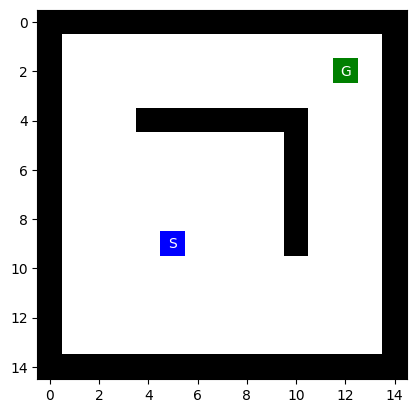

In [19]:
import numpy as np
import maze_helper as mh

f = open("L_maze.txt", "r")

maze_str = f.read()
maze = mh.parse_maze(maze_str)

mh.show_maze(maze)

## Search Helper

We need to define an expand function that will produce the neighbors for local search.

In [20]:
DIR2POS = {
    'N' : (-1, 0),
    'E' : ( 0, 1),
    'S' : ( 1, 0),
    'W' : ( 0,-1)
}

ORDER = None
RANDOMIZATION = None
DIRS = None 

# The order matters if RANDOMIZATION = False
# Note that: DFS works takes elements from the frontier in reverse order!
def set_order(order = "NESW", random = False, verbose = True):
    global RANDOMIZATION, DIR2POS, ORDER, DIRS
    
    RANDOMIZATION = random
    ORDER = [pos for pos in order]
    DIRS = [DIR2POS[dir] for dir in ORDER]
    
    if verbose:
        if RANDOMIZATION:
            print("Directions are checked at every step in random order.")
        else:
            print(f"Directions are checked in the order {ORDER}")
        
set_order("NESW", verbose = True)

Directions are checked in the order ['N', 'E', 'S', 'W']


In [21]:
def expand(maze, pos):
    """find available directions as a list of lists with elements [dir, (pos)]."""
    global RANDOMIZATION, DIRS, ORDER
       
    available = [[dir, pos] for dir, pos in zip(ORDER, np.add(pos, DIRS)) if mh.look(maze, pos) != "X"]
    if RANDOMIZATION: np.random.shuffle(available)
        
    return available

# Hill Climbing

We use Manhattan distance to the goal as the objective function (minimization).

In [22]:
# Manhattan distance h(n)
def manhattan(pos1, pos2):
    """returns the Manhattan distance between two positions"""
    return(np.sum(np.abs(np.subtract(pos1, pos2))))
    
print(manhattan([0,0], [1,1]))

2


In [23]:
def local_search(maze, vis = False, animation = False, verbose = False):
    if animation:
        maze_anim = []
    else:
        maze_anim = None
    
    # Local search starts here
    start_pos = mh.find_pos(maze, "S")
    goal_pos = mh.find_pos(maze, "G")

    current = start_pos
    current_obj = manhattan(current, goal_pos)

    while True:
        # find best neighbor
        neighbors = [n[1] for n in expand(maze, current)]
        obj = [manhattan(n, goal_pos) for n in neighbors]
        best_obj = min(obj)
        best_neighbor = neighbors[obj.index(best_obj)]

        if verbose:
            print("Current state:", current, "with obj", current_obj)
            print("Evaluating neighbors:\t", neighbors)
            print("Obj:\t\t\t", obj)


        # move there if it is an improvement or stop
        if best_obj < current_obj:
            current = best_neighbor
            current_obj = best_obj
            if verbose:
                print("Moving to:", current, "\n")
        else:
            if verbose:
                print("No better state in the neighborhood! Stopping.\n")
            break

        if animation:
            maze2 = maze.copy()
            maze2[current[0], current[1]] = "P"
            maze_anim.append(maze2)


    return { "solution" : current, "path" : None, "reached" : None, "maze_anim" : maze_anim }

## Run the Algorithm

In [24]:
%time result = local_search(maze, animation = True, verbose = True)
result["solution"]

mh.animate_maze(result)

Current state: (np.int64(9), np.int64(5)) with obj 14
Evaluating neighbors:	 [array([8, 5]), array([9, 6]), array([10,  5]), array([9, 4])]
Obj:			 [np.int64(13), np.int64(13), np.int64(15), np.int64(15)]
Moving to: [8 5] 

Current state: [8 5] with obj 13
Evaluating neighbors:	 [array([7, 5]), array([8, 6]), array([9, 5]), array([8, 4])]
Obj:			 [np.int64(12), np.int64(12), np.int64(14), np.int64(14)]
Moving to: [7 5] 

Current state: [7 5] with obj 12
Evaluating neighbors:	 [array([6, 5]), array([7, 6]), array([8, 5]), array([7, 4])]
Obj:			 [np.int64(11), np.int64(11), np.int64(13), np.int64(13)]
Moving to: [6 5] 

Current state: [6 5] with obj 11
Evaluating neighbors:	 [array([5, 5]), array([6, 6]), array([7, 5]), array([6, 4])]
Obj:			 [np.int64(10), np.int64(10), np.int64(12), np.int64(12)]
Moving to: [5 5] 

Current state: [5 5] with obj 10
Evaluating neighbors:	 [array([5, 6]), array([6, 5]), array([5, 4])]
Obj:			 [np.int64(9), np.int64(11), np.int64(11)]
Moving to: [5 6] 

Cu

**Note:** Simple hill climbing is greedy. It gets stuck in local optima!

### Nhận xét kết quả Simple Hill Climbing

**Kết quả thực nghiệm:** Thuật toán bắt đầu tại vị trí S = (9, 5), thực hiện 8 bước di chuyển và dừng tại vị trí (5, 9), với giá trị khoảng cách Manhattan giảm từ 14 xuống 6. Tuy nhiên, trạng thái cuối cùng được ghi nhận từ `result["solution"]` không trùng với vị trí đích G.

**Giải thích nguyên nhân:** Tại vị trí dừng (5, 9), hai trạng thái lân cận hợp lệ là (6, 9) và (5, 8), đều có khoảng cách Manhattan bằng 7, lớn hơn giá trị hiện tại là 6. Do thuật toán chỉ chấp nhận trạng thái lân cận làm giảm hàm mục tiêu nên không thể tiếp tục di chuyển.

**Kết luận:** Thuật toán mắc kẹt tại một cực tiểu cục bộ (local minimum). Điều này cho thấy Simple Hill Climbing có thể dừng khi chưa đến đích nếu muốn tiếp tục tìm đường phải tạm thời đi qua trạng thái có giá trị hàm mục tiêu kém hơn.

### BÀI 1 - KHẢO SÁT THỨ TỰ XÉT HƯỚNG

In [25]:
orders = ["NESW", "ESWN", "SWNE", "WNES"]

goal = mh.find_pos(maze, "G")

for order in orders:
    set_order(order, random=False, verbose=False)

    result_test = local_search(
        maze,
        vis=False,
        animation=False,
        verbose=False
    )

    stop = tuple(map(int, result_test["solution"]))
    distance = int(manhattan(stop, goal))

    print(f"\nThứ tự: {order}")
    print("Vị trí dừng:", stop)
    print("Manhattan cuối:", distance)
    print("Đến đích:", stop == tuple(goal))


Thứ tự: NESW
Vị trí dừng: (5, 9)
Manhattan cuối: 6
Đến đích: False

Thứ tự: ESWN
Vị trí dừng: (5, 9)
Manhattan cuối: 6
Đến đích: False

Thứ tự: SWNE
Vị trí dừng: (5, 9)
Manhattan cuối: 6
Đến đích: False

Thứ tự: WNES
Vị trí dừng: (5, 9)
Manhattan cuối: 6
Đến đích: False


### BÀI 1 - KHẢO SÁT THỨ TỰ DUYỆT NGẪU NHIÊN

In [26]:
import numpy as np

goal = mh.find_pos(maze, "G")

for i in range(5):
    set_order("NESW", random=True, verbose=False)

    result_test = local_search(
        maze,
        vis=False,
        animation=False,
        verbose=False
    )

    stop = tuple(map(int, result_test["solution"]))
    distance = int(manhattan(stop, goal))

    print(f"\nLần chạy {i + 1}")
    print("Vị trí dừng:", stop)
    print("Manhattan cuối:", distance)
    print("Đến đích:", stop == tuple(goal))


Lần chạy 1
Vị trí dừng: (5, 9)
Manhattan cuối: 6
Đến đích: False

Lần chạy 2
Vị trí dừng: (5, 9)
Manhattan cuối: 6
Đến đích: False

Lần chạy 3
Vị trí dừng: (5, 9)
Manhattan cuối: 6
Đến đích: False

Lần chạy 4
Vị trí dừng: (5, 9)
Manhattan cuối: 6
Đến đích: False

Lần chạy 5
Vị trí dừng: (5, 9)
Manhattan cuối: 6
Đến đích: False
